# Week 1 Task 1 — Prove why we visualize

This notebook follows the Week 1 assignment brief and keeps each task in a separate file.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

path = Path('week1/assignments/data/datasaurus.csv')
if not path.exists():
    path = Path('assignments/data/datasaurus.csv')
if not path.exists():
    path = Path('d:/7_Semester/data-visualization/week1/assignments/data/datasaurus.csv')

df = pd.read_csv(path)
summary = df.groupby('dataset').apply(lambda g: pd.Series({
    'x_mean': g['x'].mean(),
    'y_mean': g['y'].mean(),
    'x_sd': g['x'].std(ddof=1),
    'y_sd': g['y'].std(ddof=1),
    'corr': g['x'].corr(g['y'])
})).reset_index()
summary.round(3)

C:\Users\HP\AppData\Local\Temp\ipykernel_6048\3387485925.py:12: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  summary = df.groupby('dataset').apply(lambda g: pd.Series({


,dataset,x_mean,y_mean,x_sd,y_sd,corr
0,away,54.266,47.835,16.770,26.940,-0.064
1,bullseye,54.269,47.831,16.769,26.936,-0.069
2,circle,54.267,47.838,16.760,26.930,-0.068
3,dino,54.263,47.832,16.765,26.935,-0.064
4,dots,54.260,47.840,16.768,26.930,-0.060
5,h_lines,54.261,47.830,16.766,26.940,-0.062
6,high_lines,54.269,47.835,16.767,26.940,-0.069
7,slant_down,54.268,47.836,16.767,26.936,-0.069
8,slant_up,54.266,47.831,16.769,26.939,-0.069
9,star,54.267,47.840,16.769,26.930,-0.063


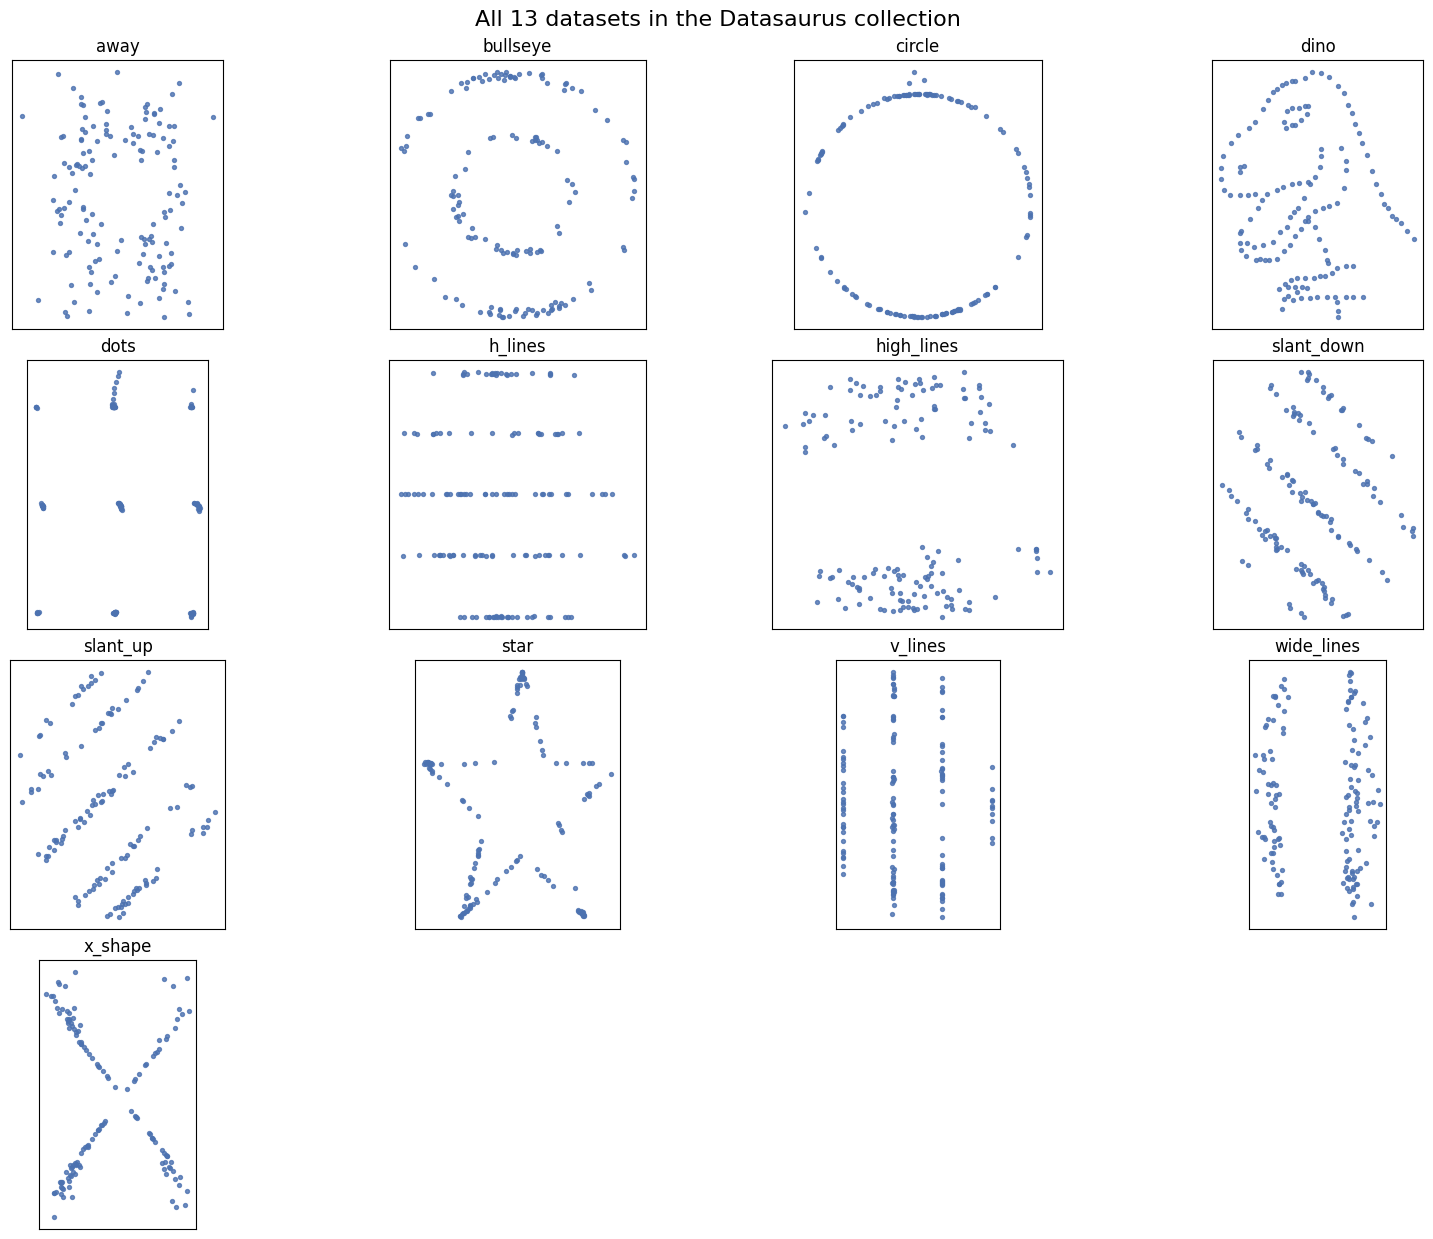

In [2]:
fig, axes = plt.subplots(4, 4, figsize=(16, 12), constrained_layout=True)
for ax, (name, group) in zip(axes.flat, df.groupby('dataset')):
    ax.scatter(group['x'], group['y'], s=8, color='#4c72b0', alpha=0.8)
    ax.set_title(name)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect('equal', adjustable='box')
for ax in axes.flat[len(df['dataset'].unique()):]:
    ax.set_visible(False)
fig.suptitle('All 13 datasets in the Datasaurus collection', fontsize=16, y=1.02)
plt.show()

In [ ]:
# The summary statistics are nearly identical across datasets, but the scatter plots show different shapes. This proves that summary statistics alone can hide important structure and that visualizing the data is essential.